# Growth of Piura, Peru, 2020-2025
**856.114 GeoHumanitarian Action - Homework Assignment 2**

World Population Review calls Piura the fastest growing city in Peru. This notebook tests that claim
for 2020-2025 with rasterized population data and building data. **No Google Earth Engine account is
needed**: every dataset is read from an open source.

| Data | Source | Read with |
|---|---|---|
| Building footprints (Microsoft, Google, OSM) | published datasets | pygeovision `building_footprints` |
| Built-up change 2020-2023 (Esri 10 m land cover) | Microsoft Planetary Computer | pygeovision `urban_expansion` |
| Sentinel-2 L2A true colour | Microsoft Planetary Computer | pygeovision grid reader |
| Population, built-up surface, built-up volume 2020 and 2025 (GHSL R2023A, 100 m) | JRC open-data server | rasterio |

1. Do the datasets show the same growth rate as the web source?
2. What is the annual growth rate of building footprint extent?
3. Where is the city growing in extent?
4. Where do we observe growth in building volume?

### Setup
Run the next cell once to install the packages (Colab or a fresh environment). No Earth Engine or other account is needed; all data are open.

In [1]:
%pip install -q "pygeovision[geo]==2.2.0" geopandas rasterio shapely pyproj requests folium matplotlib reportlab python-docx openpyxl

In [2]:
# Stand-in for marimo's mo.md: renders as Markdown in Jupyter, and as readable text in editors
# that only show plain text (instead of <IPython.core.display.Markdown object>)
from IPython.display import Markdown


class _Md(Markdown):
    def __repr__(self):
        return self.data


class mo:
    md = staticmethod(_Md)


%matplotlib inline

In [3]:
west, south, east, north = -80.625, -5.180, -80.610, -5.165  # AOI: north-eastern urban edge of Piura
AOI_BBOX = (west, south, east, north)
CITY_BBOX = (-80.70, -5.26, -80.55, -5.13)  # rectangle around the whole city
UTM = "EPSG:32717"  # UTM zone 17S (Piura)
MOLL = "ESRI:54009"  # World Mollweide, the native grid of GHSL
EPOCHS = (2020, 2025)  # GHSL epochs (2025 is a model projection)
ESRI_YEARS = (2020, 2023)  # Esri annual land cover ends in 2023
OUT_DIR = "piura_out"  # pygeovision writes its rasters, vectors and reports here
CACHE = "piura_cache"  # downloaded GHSL tiles are kept here

In [4]:
import zipfile
from pathlib import Path

import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import rasterio.mask
import requests
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Rectangle
from pyproj import Transformer
from rasterio.features import rasterize
from shapely.geometry import box

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11})

In [5]:
FIG_DIR = Path("figures")  # every figure is also saved here as a PNG (use these in the report)

def save_fig(fig, name):
    """Save a figure to figures/<name>.png at print quality and return it for display."""
    FIG_DIR.mkdir(exist_ok=True)
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    print(f"Figure saved: {FIG_DIR / (name + '.png')}")
    return fig

def cagr(v_start, v_end, years):
    """Compound annual growth rate: (V_end / V_start)^(1/n) - 1."""
    return (v_end / v_start) ** (1 / years) - 1

SECTOR_NAMES = [["NW", "N", "NE"], ["W", "Centre", "E"], ["SW", "S", "SE"]]

def sector_table(a, label):
    """Split a north-up array into a 3 x 3 grid of sectors and sum each sector."""
    h, w = a.shape
    rows = []
    for i in range(3):
        for j in range(3):
            part = a[i * h // 3:(i + 1) * h // 3, j * w // 3:(j + 1) * w // 3]
            rows.append({"sector": SECTOR_NAMES[i][j], label: float(np.nansum(part))})
    df = pd.DataFrame(rows)
    total = df[label].clip(lower=0).sum()
    df["share_of_gain_%"] = (100 * df[label].clip(lower=0) / total).round(1) if total > 0 else 0.0
    return df.sort_values(label, ascending=False).reset_index(drop=True)

In [6]:
aoi_ll = box(*AOI_BBOX)
city_ll = box(*CITY_BBOX)
aoi_utm = gpd.GeoSeries([aoi_ll], crs=4326).to_crs(UTM)
aoi_bounds = aoi_utm.total_bounds  # x0, y0, x1, y1 in metres
aoi_km2 = float(aoi_utm.area.iloc[0]) / 1e6
aoi_moll = gpd.GeoSeries([aoi_ll], crs=4326).to_crs(MOLL).iloc[0]
city_moll = gpd.GeoSeries([city_ll], crs=4326).to_crs(MOLL).iloc[0]
mo.md(
    f"AOI: **{(aoi_bounds[2] - aoi_bounds[0]) / 1000:.2f} km x "
    f"{(aoi_bounds[3] - aoi_bounds[1]) / 1000:.2f} km = {aoi_km2:.2f} km²** (UTM 17S)"
)

AOI: **1.66 km x 1.66 km = 2.76 km²** (UTM 17S)

## 1. Building footprints with pygeovision
The `building_footprints` pipeline reads a published footprint dataset for the box, clips it,
measures every polygon in the local UTM zone (`area_m2`) and writes a GeoPackage plus 100 m
building density and count rasters. It is run three times, once per source. No account is needed.

In [7]:
from pygeovision import PyGeoVision
from pygeovision.data.reference import PlanetaryComputer, make_grid, read_to_grid

pgv = PyGeoVision()
_s = pgv.status()
mo.md(
    f"pygeovision **{_s['pygeovision_version']}** (pygeofetch "
    f"{_s['pygeofetch'].get('version', '?') if isinstance(_s['pygeofetch'], dict) else _s['pygeofetch']}, "
    f"rasterio {_s['rasterio']}, geopandas {_s['geopandas']})"
)

08:51:01 INFO [      engine] PyGeoFetch ready


pygeovision **2.2.0** (pygeofetch 2.6.9.6.4, rasterio 1.5.2, geopandas 1.2.0)

In [8]:
FOOTPRINT_SOURCES = {"Microsoft": "microsoft", "Google": "google", "OSM": "osm"}
fp_results = {}
for _label, _src in FOOTPRINT_SOURCES.items():
    _extra = {"min_confidence": 0.75} if _src == "google" else {}  # same threshold as Session 2
    fp_results[_label] = pgv.pipeline(
        "building_footprints",
        bbox=AOI_BBOX,
        source=_src,
        cell_m=100,
        output_dir=f"{OUT_DIR}/footprints_{_src}",
        report=False,  # skip pygeovision's own PDF/Word/Excel reports
        **_extra,
    )

pd.DataFrame(
    [
        {"source": k, "success": r.success, "message": (r.error or "ok")[:150]}
        for k, r in fp_results.items()
    ]
)

INFO:pygeovision.data.footprints:Microsoft footprints: 604 buildings from 1 partition file(s)
INFO:pyogrio._io:Created 604 records
INFO:pygeovision.data.footprints:Google Open Buildings: 1141 buildings from 1 file(s)
INFO:pyogrio._io:Created 1,141 records
INFO:pygeovision.data.footprints:OpenStreetMap: 321 building feature(s)
INFO:pyogrio._io:Created 321 records


,source,success,message
0,Microsoft,True,ok
1,Google,True,ok
2,OSM,True,ok


In [9]:
def _r(v, n=1):
    return None if v is None else round(v, n)

fp_table = pd.DataFrame(
    [
        {
            "source": _label,
            "buildings": _res.stats["building_count"],
            "footprint_area_ha": _r(_res.stats["building_area_ha"], 2),
            "coverage_%": _r(100 * _res.stats["building_coverage"]),
            "buildings_per_km2": _r(_res.stats["buildings_per_km2"], 0),
            "mean_area_m2": _r(_res.stats["mean_building_area_m2"]),
            "median_area_m2": _r(_res.stats["median_building_area_m2"]),
            "mean_height_m": _r(_res.stats.get("mean_height_m")),
        }
        for _label, _res in fp_results.items()
        if _res.success
    ]
)
fp_table

,source,buildings,footprint_area_ha,coverage_%,buildings_per_km2,mean_area_m2,median_area_m2,mean_height_m
0,Microsoft,604,13.83,5.0,219.0,228.9,141.0,None
1,Google,1141,17.27,6.3,414.0,151.4,95.4,None
2,OSM,321,9.68,3.5,116.0,301.5,177.0,None


In [10]:
buildings = {}
for _label, _res in fp_results.items():
    _f = _res.stats.get("footprints_file") if _res.success else None
    buildings[_label] = (
        gpd.read_file(_f, layer="buildings").to_crs(UTM) if _f else gpd.GeoDataFrame(geometry=[], crs=UTM)
    )
{k: len(v) for k, v in buildings.items()}

{'Microsoft': 604, 'Google': 1141, 'OSM': 321}

Figure saved: figures/fig_osm.png


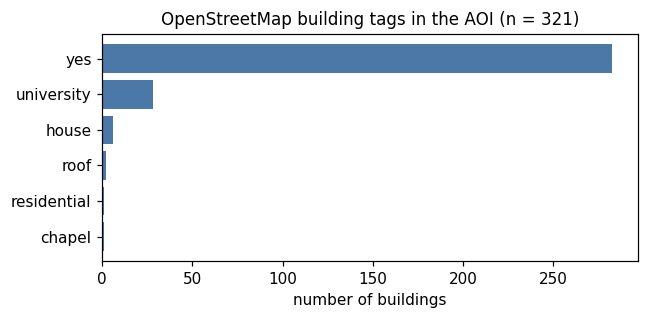

In [11]:
_osm = buildings["OSM"]
if len(_osm) and "building" in _osm.columns:
    osm_tags = _osm["building"].fillna("unknown").value_counts().rename_axis("building").reset_index(name="count")
else:
    osm_tags = pd.DataFrame({"building": [], "count": []})

fig_osm, _ax = plt.subplots(figsize=(6, 3))
_ax.barh(osm_tags["building"][::-1], osm_tags["count"][::-1], color="#4c78a8")
_ax.set_xlabel("number of buildings")
_ax.set_title(f"OpenStreetMap building tags in the AOI (n = {int(osm_tags['count'].sum())})")
fig_osm.tight_layout()
save_fig(fig_osm, "fig_osm")
plt.show()

In [12]:
pc = PlanetaryComputer()
_end = pd.Timestamp.now().normalize()
_start = _end - pd.DateOffset(years=1)
_items = pc.search("sentinel-2-l2a", AOI_BBOX, datetime=f"{_start:%Y-%m-%d}/{_end:%Y-%m-%d}")
_items = [i for i in _items if i["properties"].get("eo:cloud_cover", 100) < 50]

# group the scenes by acquisition date (the AOI may touch two Sentinel-2 tiles on the same day)
_by_date = {}
for _it in _items:
    _by_date.setdefault(_it["properties"]["datetime"][:10], []).append(_it)
_dates = sorted(_by_date, reverse=True)

_grid20 = make_grid(AOI_BBOX, 20, UTM)
best_date, best_items, _checked = None, None, 0
for _d in _dates[:25]:
    _checked += 1
    _scl = read_to_grid(pc.asset_urls("sentinel-2-l2a", _by_date[_d], "SCL"), _grid20).data
    _valid = np.isfinite(_scl)
    _cloudy = np.isin(_scl, [3, 8, 9, 10]) | ~_valid  # cloud shadow, cloud, cirrus or no data
    if _cloudy.mean() < 0.05:
        best_date, best_items = pd.Timestamp(_d), _by_date[_d]
        break
if best_date is None:
    raise RuntimeError("No cloud-free Sentinel-2 date over the AOI in the last 12 months.")
mo.md(
    f"{len(_dates)} Sentinel-2 dates with < 50 % scene cloud in the last 12 months; checked {_checked} over the AOI. "
    f"Using **{best_date.date()}** ({', '.join(i['id'] for i in best_items)})."
)

76 Sentinel-2 dates with < 50 % scene cloud in the last 12 months; checked 2 over the AOI. Using **2026-10-05** (S2B_MSIL2A_20261005T155219_R111_T17MNQ_20261005T204634).

In [13]:
grid10 = make_grid(AOI_BBOX, 10, UTM)
_urls = pc.asset_urls("sentinel-2-l2a", best_items, "visual")  # 8-bit true-colour composite (TCI)
rgb = np.dstack([read_to_grid(_urls, grid10, band=_b, resampling="bilinear").data for _b in (1, 2, 3)])
rgb = np.clip(np.nan_to_num(rgb) / 255.0, 0, 1)
_l, _b, _r, _t = grid10.bounds
s2_extent = [_l, _r, _b, _t]

Figure saved: figures/fig_study.png


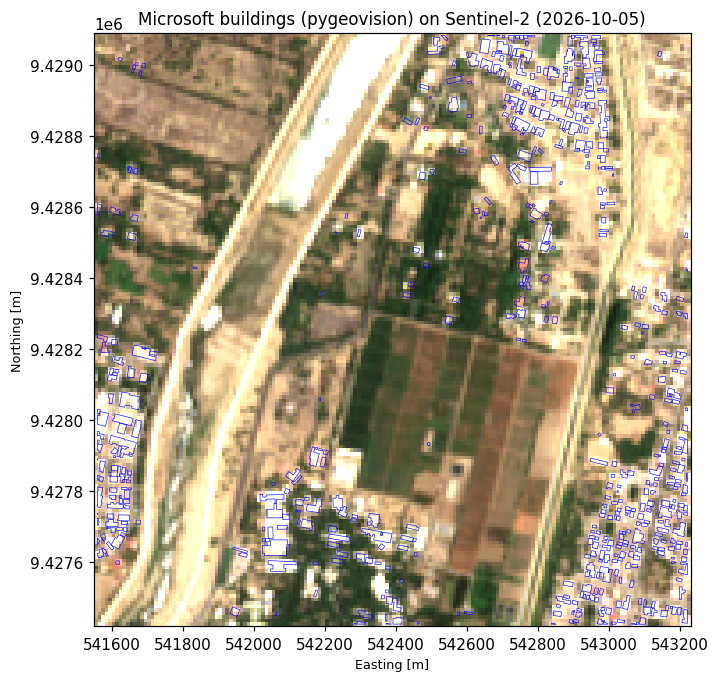

In [14]:
fig_study, _ax = plt.subplots(figsize=(7, 7))
_ax.imshow(rgb, extent=s2_extent)
if len(buildings["Microsoft"]):
    buildings["Microsoft"].plot(ax=_ax, facecolor="none", edgecolor="blue", linewidth=0.4)
_ax.set_title(f"Microsoft buildings (pygeovision) on Sentinel-2 ({best_date:%Y-%m-%d})")
_ax.set_xlabel("Easting [m]")
_ax.set_ylabel("Northing [m]")
save_fig(fig_study, "fig_study")
plt.show()

Figure saved: figures/fig_cmp.png


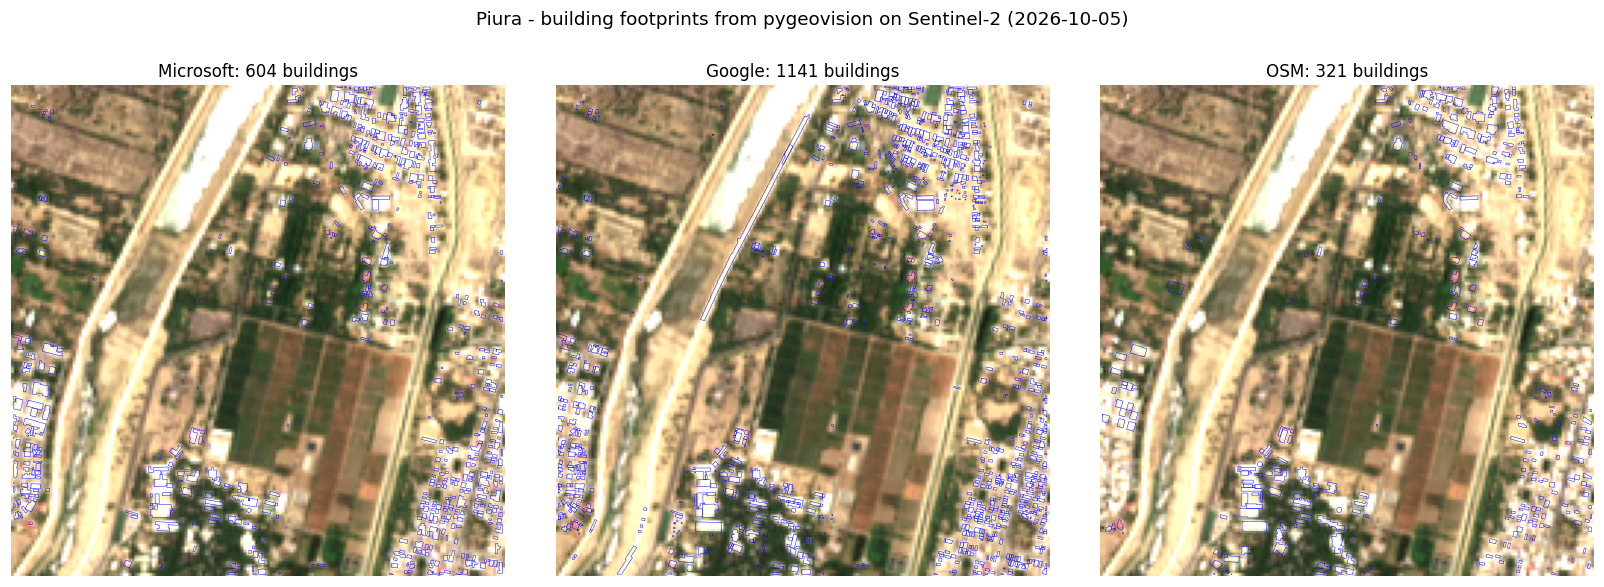

In [15]:
fig_cmp, _axes = plt.subplots(1, 3, figsize=(15, 5.4))
for _ax, (_name, _gdf) in zip(_axes, buildings.items()):
    _ax.imshow(rgb, extent=s2_extent)
    if len(_gdf):
        _gdf.plot(ax=_ax, facecolor="none", edgecolor="blue", linewidth=0.3)
    _ax.set_title(f"{_name}: {len(_gdf)} buildings")
    _ax.set_axis_off()
fig_cmp.suptitle(f"Piura - building footprints from pygeovision on Sentinel-2 ({best_date:%Y-%m-%d})")
fig_cmp.tight_layout(rect=[0, 0, 1, 0.94])
save_fig(fig_cmp, "fig_cmp")
plt.show()

Figure saved: figures/fig_size.png


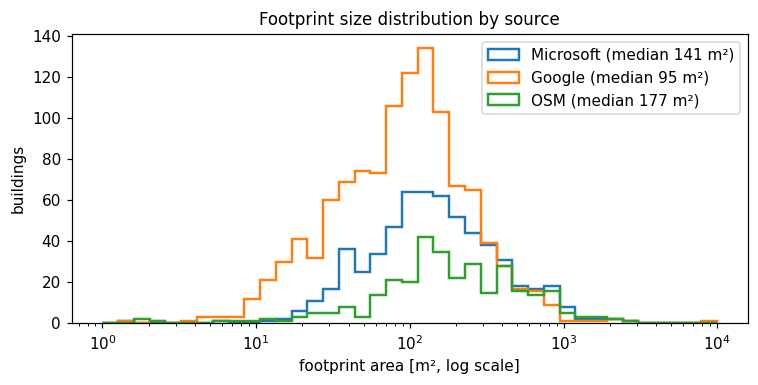

In [16]:
fig_size, _ax = plt.subplots(figsize=(7, 3.6))
_bins = np.logspace(0, 4, 40)
for _name, _gdf in buildings.items():
    if len(_gdf):
        _ax.hist(_gdf["area_m2"], bins=_bins, histtype="step", linewidth=1.6,
                 label=f"{_name} (median {_gdf['area_m2'].median():.0f} m²)")
_ax.set_xscale("log")
_ax.set_xlabel("footprint area [m², log scale]")
_ax.set_ylabel("buildings")
_ax.set_title("Footprint size distribution by source")
_ax.legend()
fig_size.tight_layout()
save_fig(fig_size, "fig_size")
plt.show()

Figure saved: figures/fig_density.png


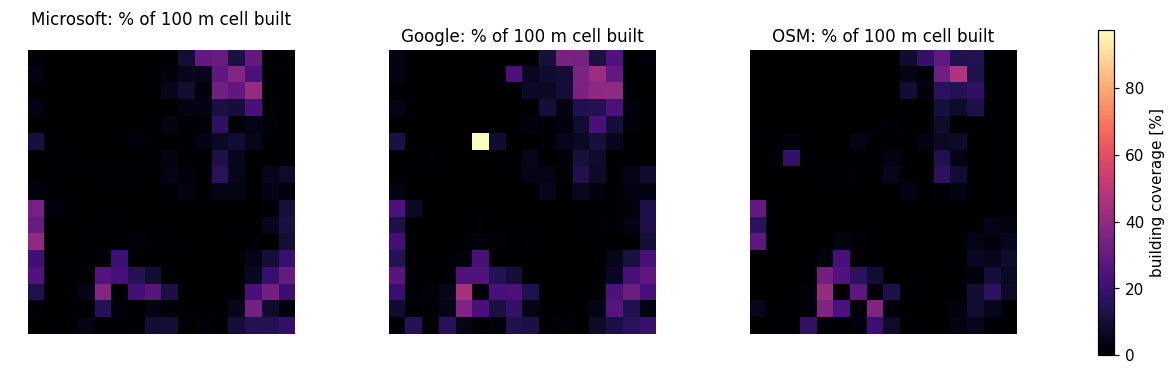

In [17]:
_dens = {}
for _name, _res in fp_results.items():
    if _res.success:
        with rasterio.open(_res.output_path) as _src:
            _b = _src.bounds
            _dens[_name] = (_src.read(1), [_b.left, _b.right, _b.bottom, _b.top])
_vmax = max([np.nanmax(d[0]) for d in _dens.values()] + [0.01])
fig_density, _axes = plt.subplots(1, max(len(_dens), 1), figsize=(15, 4.8), squeeze=False)
for _ax, (_name, (_arr, _ext)) in zip(_axes[0], _dens.items()):
    _im = _ax.imshow(100 * _arr, extent=_ext, cmap="magma", vmin=0, vmax=100 * _vmax)
    _ax.set_title(f"{_name}: % of 100 m cell built")
    _ax.set_axis_off()
fig_density.colorbar(_im, ax=_axes[0].tolist(), shrink=0.8, label="building coverage [%]")
save_fig(fig_density, "fig_density")
plt.show()

In [18]:
_center = [(south + north) / 2, (west + east) / 2]
m_toggle = folium.Map(location=_center, zoom_start=16, max_zoom=21, tiles=None)
folium.TileLayer(
    "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Imagery", name="Esri satellite", max_zoom=21, max_native_zoom=19,
).add_to(m_toggle)
_colors = {"Microsoft": "red", "Google": "yellow", "OSM": "magenta"}
for _name, _gdf in buildings.items():
    if len(_gdf):
        _light = _gdf[["area_m2", "geometry"]].copy()
        _light["geometry"] = _light.geometry.simplify(0.5)
        folium.GeoJson(
            _light.to_crs(4326),
            name=f"{_name} ({len(_gdf)})",
            style_function=lambda _f, c=_colors[_name]: {"color": c, "weight": 1, "fillOpacity": 0},
            show=(_name == "Microsoft"),
        ).add_to(m_toggle)
folium.Rectangle([[south, west], [north, east]], color="white", weight=2, fill=False, name="AOI").add_to(m_toggle)
folium.LayerControl(collapsed=False).add_to(m_toggle)
FIG_DIR.mkdir(exist_ok=True)
m_toggle.save(str(FIG_DIR / "interactive_map.html"))  # open in a browser if the map does not show inline
m_toggle

## 2. GHSL rasters from the JRC open-data server
The Global Human Settlement Layer R2023A is published as 100 m GeoTIFF tiles (World Mollweide) for
5-year epochs. Three products are used, each for 2020 and 2025:

* **GHS_POP** - residential population per cell (people)
* **GHS_BUILT_S** - built-up surface per cell (m²), i.e. the footprint extent
* **GHS_BUILT_V** - built-up volume per cell (m³)

The notebook works out which tile holds Piura, downloads each tile once into the cache folder and checks
that the tile really covers the AOI and the city box.

In [19]:
JRC = "https://jeodpp.jrc.ec.europa.eu/ftp/jrc-opendata/GHSL"
_x, _y = Transformer.from_crs(4326, MOLL, always_xy=True).transform(
    (AOI_BBOX[0] + AOI_BBOX[2]) / 2, (AOI_BBOX[1] + AOI_BBOX[3]) / 2)
# GHSL 100 m tiles are 1000 km x 1000 km, counted from x = -18 041 000 m, y = 9 000 000 m
TILE_ROW = int((9_000_000 - _y) // 1_000_000) + 1
TILE_COL = int((_x + 18_041_000) // 1_000_000) + 1

def ghsl_path(product, epoch):
    """Download (once) the GHSL tile of `product` and `epoch` and return a path rasterio can open."""
    name = f"GHS_{product}_E{epoch}_GLOBE_R2023A_54009_100_V1_0_R{TILE_ROW}_C{TILE_COL}"
    url = f"{JRC}/GHS_{product}_GLOBE_R2023A/GHS_{product}_E{epoch}_GLOBE_R2023A_54009_100/V1-0/tiles/{name}.zip"
    local = Path(CACHE) / f"{name}.zip"
    if not local.exists():
        local.parent.mkdir(parents=True, exist_ok=True)
        with requests.get(url, stream=True, timeout=900, headers={"User-Agent": "piura-assignment/1.0"}) as r:
            r.raise_for_status()
            part = local.with_suffix(".part")
            with open(part, "wb") as fh:
                for chunk in r.iter_content(1 << 20):
                    fh.write(chunk)
            part.rename(local)
    with zipfile.ZipFile(local) as z:
        tif = next(n for n in z.namelist() if n.lower().endswith(".tif"))
    return f"/vsizip/{local}/{tif}"

mo.md(f"Piura lies in GHSL tile **R{TILE_ROW}_C{TILE_COL}**.")

Piura lies in GHSL tile **R10_C10**.

In [20]:
ghsl = {(_p, _e): ghsl_path(_p, _e) for _p in ("POP", "BUILT_S", "BUILT_V") for _e in EPOCHS}
for (_p, _e), _path in ghsl.items():
    with rasterio.open(_path) as _src:
        assert box(*_src.bounds).contains(city_moll) and box(*_src.bounds).contains(aoi_moll), (
            f"tile for {_p} {_e} does not cover the study area")
mo.md("All six GHSL tiles downloaded and checked: " + ", ".join(f"{p} {e}" for p, e in ghsl))

All six GHSL tiles downloaded and checked: POP 2020, POP 2025, BUILT_S 2020, BUILT_S 2025, BUILT_V 2020, BUILT_V 2025

In [21]:
def ghsl_sum(path, geom_moll):
    """Sum of a GHSL tile over a polygon (Mollweide), counting the 100 m cells whose centre is inside."""
    with rasterio.open(path) as src:
        arr, _ = rasterio.mask.mask(src, [geom_moll], crop=True, filled=False)
        arr = np.ma.masked_less(np.ma.masked_equal(arr, src.nodata) if src.nodata is not None else arr, 0)
    return float(arr.sum())

## 3. Question 1 - Do the datasets show the same growth rate as the web source?
Web source: World Population Review, *Piura Population 2026*. Raster: GHSL GHS_POP R2023A, 100 m,
epochs 2020 and 2025 (2025 is a model projection). Rates are compound annual growth rates.

In [22]:
WPR = {"pop_1993": 272_231, "pop_2026": 609_909, "growth_last_year": 16_348}
wpr_2025 = WPR["pop_2026"] - WPR["growth_last_year"]
wpr_rate_1y = WPR["growth_last_year"] / wpr_2025
wpr_rate_long = cagr(WPR["pop_1993"], WPR["pop_2026"], 2026 - 1993)

In [23]:
_y0, _y1 = EPOCHS
pop_table = pd.DataFrame(
    {
        "area": ["AOI", "City box"],
        f"pop_{_y0}": [ghsl_sum(ghsl["POP", _y0], aoi_moll), ghsl_sum(ghsl["POP", _y0], city_moll)],
        f"pop_{_y1}": [ghsl_sum(ghsl["POP", _y1], aoi_moll), ghsl_sum(ghsl["POP", _y1], city_moll)],
    }
)
pop_table["growth_%_per_year"] = [
    round(100 * cagr(a, b, _y1 - _y0), 2) for a, b in zip(pop_table[f"pop_{_y0}"], pop_table[f"pop_{_y1}"])
]
pop_table

,area,pop_2020,pop_2025,growth_%_per_year
0,AOI,3602.934734,4165.159706,2.94
1,City box,493019.688398,522191.164703,1.16


Figure saved: figures/fig_rates.png


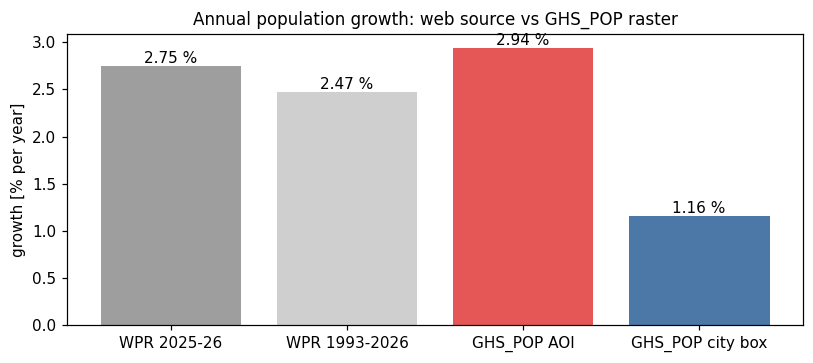

In [24]:
rate_table = pd.DataFrame(
    [
        {"measure": "World Population Review, whole city", "period": "2025-2026 (one year)",
         "population": f"{wpr_2025:,} -> {WPR['pop_2026']:,}", "growth_%_per_year": round(100 * wpr_rate_1y, 2)},
        {"measure": "World Population Review, whole city", "period": "1993-2026 (average)",
         "population": f"{WPR['pop_1993']:,} -> {WPR['pop_2026']:,}", "growth_%_per_year": round(100 * wpr_rate_long, 2)},
        {"measure": "GHS_POP, AOI", "period": "2020-2025 (CAGR)",
         "population": f"{pop_table.iloc[0, 1]:,.0f} -> {pop_table.iloc[0, 2]:,.0f}",
         "growth_%_per_year": pop_table.iloc[0, 3]},
        {"measure": "GHS_POP, city box", "period": "2020-2025 (CAGR)",
         "population": f"{pop_table.iloc[1, 1]:,.0f} -> {pop_table.iloc[1, 2]:,.0f}",
         "growth_%_per_year": pop_table.iloc[1, 3]},
    ]
)
fig_rates, _ax = plt.subplots(figsize=(7.5, 3.4))
_labels = ["WPR 2025-26", "WPR 1993-2026", "GHS_POP AOI", "GHS_POP city box"]
_bars = _ax.bar(_labels, rate_table["growth_%_per_year"], color=["#9e9e9e", "#cfcfcf", "#e45756", "#4c78a8"])
_ax.bar_label(_bars, fmt="%.2f %%")
_ax.set_ylabel("growth [% per year]")
_ax.set_title("Annual population growth: web source vs GHS_POP raster")
fig_rates.tight_layout()
save_fig(fig_rates, "fig_rates")
plt.show()

In [ ]:
rate_table

Figure saved: figures/fig_popmap.png


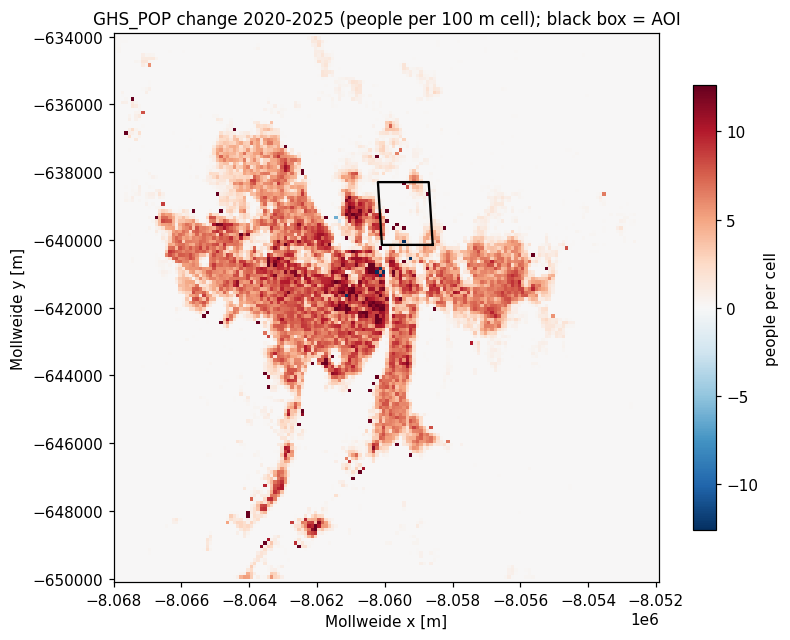

In [25]:
def _window(path):
    with rasterio.open(path) as src:
        arr, tr = rasterio.mask.mask(src, [city_moll], crop=True, filled=True, nodata=0)
    return np.where(arr[0] < 0, 0, arr[0]).astype(float), tr

_p0, _tr = _window(ghsl["POP", EPOCHS[0]])
_p1, _ = _window(ghsl["POP", EPOCHS[1]])
pop_change = _p1 - _p0
_ext = [_tr.c, _tr.c + _tr.a * pop_change.shape[1], _tr.f + _tr.e * pop_change.shape[0], _tr.f]
_lim = np.nanpercentile(np.abs(pop_change[pop_change != 0]), 99) if np.any(pop_change) else 1
fig_popmap, _ax = plt.subplots(figsize=(8, 7))
_im = _ax.imshow(pop_change, cmap="RdBu_r", vmin=-_lim, vmax=_lim, extent=_ext)
_ax.plot(*aoi_moll.exterior.xy, color="black", linewidth=1.5)
_ax.set_title(f"GHS_POP change {EPOCHS[0]}-{EPOCHS[1]} (people per 100 m cell); black box = AOI")
_ax.set_xlabel("Mollweide x [m]")
_ax.set_ylabel("Mollweide y [m]")
fig_popmap.colorbar(_im, ax=_ax, shrink=0.75, label="people per cell")
save_fig(fig_popmap, "fig_popmap")
plt.show()

## 4. Question 2 - Annual growth rate of building footprint extent
Footprint extent = GHS_BUILT_S (built-up surface, m²) summed over the area, 2020 and 2025.
Building volume = GHS_BUILT_V (m³). Mean building height = volume ÷ surface.
A second, independent estimate comes from the Esri 10 m annual land cover through pygeovision
`urban_expansion` (2020 to 2023, the last year of that product).

In [26]:
_y0, _y1 = EPOCHS
_n = _y1 - _y0
_rows = []
for _area, _geom in [("AOI", aoi_moll), ("City box", city_moll)]:
    _s0, _s1 = ghsl_sum(ghsl["BUILT_S", _y0], _geom), ghsl_sum(ghsl["BUILT_S", _y1], _geom)
    _v0, _v1 = ghsl_sum(ghsl["BUILT_V", _y0], _geom), ghsl_sum(ghsl["BUILT_V", _y1], _geom)
    _rows.append({
        "area": _area,
        f"surface_{_y0}_m2": _s0, f"surface_{_y1}_m2": _s1, "surface_growth_%_per_year": 100 * cagr(_s0, _s1, _n),
        f"volume_{_y0}_m3": _v0, f"volume_{_y1}_m3": _v1, "volume_growth_%_per_year": 100 * cagr(_v0, _v1, _n),
        f"mean_height_{_y0}_m": _v0 / _s0, f"mean_height_{_y1}_m": _v1 / _s1,
    })
built_table = pd.DataFrame(_rows)
fp_cagr = built_table.loc[0, "surface_growth_%_per_year"] / 100
vol_cagr = built_table.loc[0, "volume_growth_%_per_year"] / 100
print(f"Annual growth of building footprint extent (GHS_BUILT_S, AOI) {_y0}-{_y1}: {100 * fp_cagr:.2f} % per year")
print(f"Annual growth of building volume           (GHS_BUILT_V, AOI) {_y0}-{_y1}: {100 * vol_cagr:.2f} % per year")
built_table.round(2)

Annual growth of building footprint extent (GHS_BUILT_S, AOI) 2020-2025: 1.70 % per year
Annual growth of building volume           (GHS_BUILT_V, AOI) 2020-2025: 1.97 % per year


,area,surface_2020_m2,surface_2025_m2,surface_growth_%_per_year,volume_2020_m3,volume_2025_m3,volume_growth_%_per_year,mean_height_2020_m,mean_height_2025_m
0,AOI,204630.0,222670.0,1.70,982256.0,1083125.0,1.97,4.80,4.86
1,City box,19288726.0,19416605.0,0.13,138365117.0,138934212.0,0.08,7.17,7.16


In [27]:
ue_result = pgv.pipeline(
    "urban_expansion",
    bbox=AOI_BBOX,
    date_before=str(ESRI_YEARS[0]),
    date_after=str(ESRI_YEARS[1]),
    output_dir=f"{OUT_DIR}/urban_expansion",
    report=False,  # skip pygeovision's own PDF/Word/Excel reports
)
print("success:", ue_result.success, "|", ue_result.error or "")
{k: v for k, v in (ue_result.stats or {}).items() if k != "product_note"}

success: True | 


{'year_before': 2020,
 'year_after': 2023,
 'built_area_ha_before': 172.06,
 'built_area_ha_after': 177.66,
 'gain_ha': 16.77,
 'loss_ha': 11.17,
 'net_change_ha': 5.599999999999994,
 'built_share_before': np.float64(0.6132734530938124),
 'built_share_after': np.float64(0.6332335329341318),
 'annual_growth_rate': 0.010733312497621439,
 'valid_fraction': 1.0,
 'resolution_m': 10.0,
 'resolution_coarsened': False}

Figure saved: figures/fig_growth.png


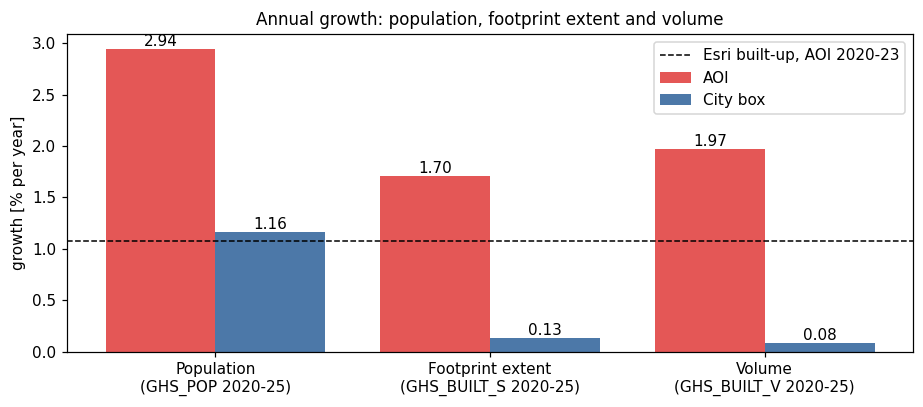

In [28]:
_labels = ["Population\n(GHS_POP 2020-25)", "Footprint extent\n(GHS_BUILT_S 2020-25)", "Volume\n(GHS_BUILT_V 2020-25)"]
_aoi = [pop_table.iloc[0, 3], built_table.loc[0, "surface_growth_%_per_year"], built_table.loc[0, "volume_growth_%_per_year"]]
_city = [pop_table.iloc[1, 3], built_table.loc[1, "surface_growth_%_per_year"], built_table.loc[1, "volume_growth_%_per_year"]]
fig_growth, _ax = plt.subplots(figsize=(8.5, 3.8))
_x = range(len(_labels))
_b1 = _ax.bar([i - 0.2 for i in _x], _aoi, width=0.4, color="#e45756", label="AOI")
_b2 = _ax.bar([i + 0.2 for i in _x], _city, width=0.4, color="#4c78a8", label="City box")
_ax.bar_label(_b1, fmt="%.2f")
_ax.bar_label(_b2, fmt="%.2f")
if ue_result.success:
    _ax.axhline(100 * ue_result.stats["annual_growth_rate"], color="black", linestyle="--", linewidth=1,
                label="Esri built-up, AOI 2020-23")
_ax.set_xticks(list(_x))
_ax.set_xticklabels(_labels)
_ax.set_ylabel("growth [% per year]")
_ax.set_title("Annual growth: population, footprint extent and volume")
_ax.legend()
fig_growth.tight_layout()
save_fig(fig_growth, "fig_growth")
plt.show()

In [29]:
_rows = [
    {"source": f"GHS_BUILT_S {EPOCHS[0]}", "area_ha": built_table.iloc[0, 1] / 1e4, "annual_growth_%": None},
    {"source": f"GHS_BUILT_S {EPOCHS[1]}", "area_ha": built_table.iloc[0, 2] / 1e4,
     "annual_growth_%": built_table.loc[0, "surface_growth_%_per_year"]},
]
if ue_result.success:
    _s = ue_result.stats
    _rows += [
        {"source": f"Esri 10 m land cover {ESRI_YEARS[0]}", "area_ha": _s["built_area_ha_before"], "annual_growth_%": None},
        {"source": f"Esri 10 m land cover {ESRI_YEARS[1]}", "area_ha": _s["built_area_ha_after"],
         "annual_growth_%": 100 * _s["annual_growth_rate"]},
    ]
for _name, _res in fp_results.items():
    if _res.success:
        _rows.append({"source": f"{_name} footprints (snapshot)", "area_ha": _res.stats["building_area_ha"],
                      "annual_growth_%": None})
area_check = pd.DataFrame(_rows).round(2)
area_check

,source,area_ha,annual_growth_%
0,GHS_BUILT_S 2020,20.46,NaN
1,GHS_BUILT_S 2025,22.27,1.70
2,Esri 10 m land cover 2020,172.06,NaN
3,Esri 10 m land cover 2023,177.66,1.07
4,Microsoft footprints (snapshot),13.83,NaN
5,Google footprints (snapshot),17.27,NaN
6,OSM footprints (snapshot),9.68,NaN


## 5. Question 3 - Where is the city growing in extent?
GHSL is resampled from its Mollweide tile to a 100 m grid in UTM 17S so it can be drawn over the
Sentinel-2 image and the footprints. The Esri land cover gives the same question at 10 m.

In [30]:
grid100 = make_grid(AOI_BBOX, 100, UTM)

def _g(product, epoch):
    return np.nan_to_num(read_to_grid([ghsl[product, epoch]], grid100, resampling="nearest",
                                      invalid_values=[65535, -200]).data)

surf = {_e: _g("BUILT_S", _e) for _e in EPOCHS}
vol = {_e: _g("BUILT_V", _e) for _e in EPOCHS}
_l, _b, _r, _t = grid100.bounds
extent100 = [_l, _r, _b, _t]
dsurf = surf[EPOCHS[1]] - surf[EPOCHS[0]]
dvol = vol[EPOCHS[1]] - vol[EPOCHS[0]]

Figure saved: figures/fig_new.png


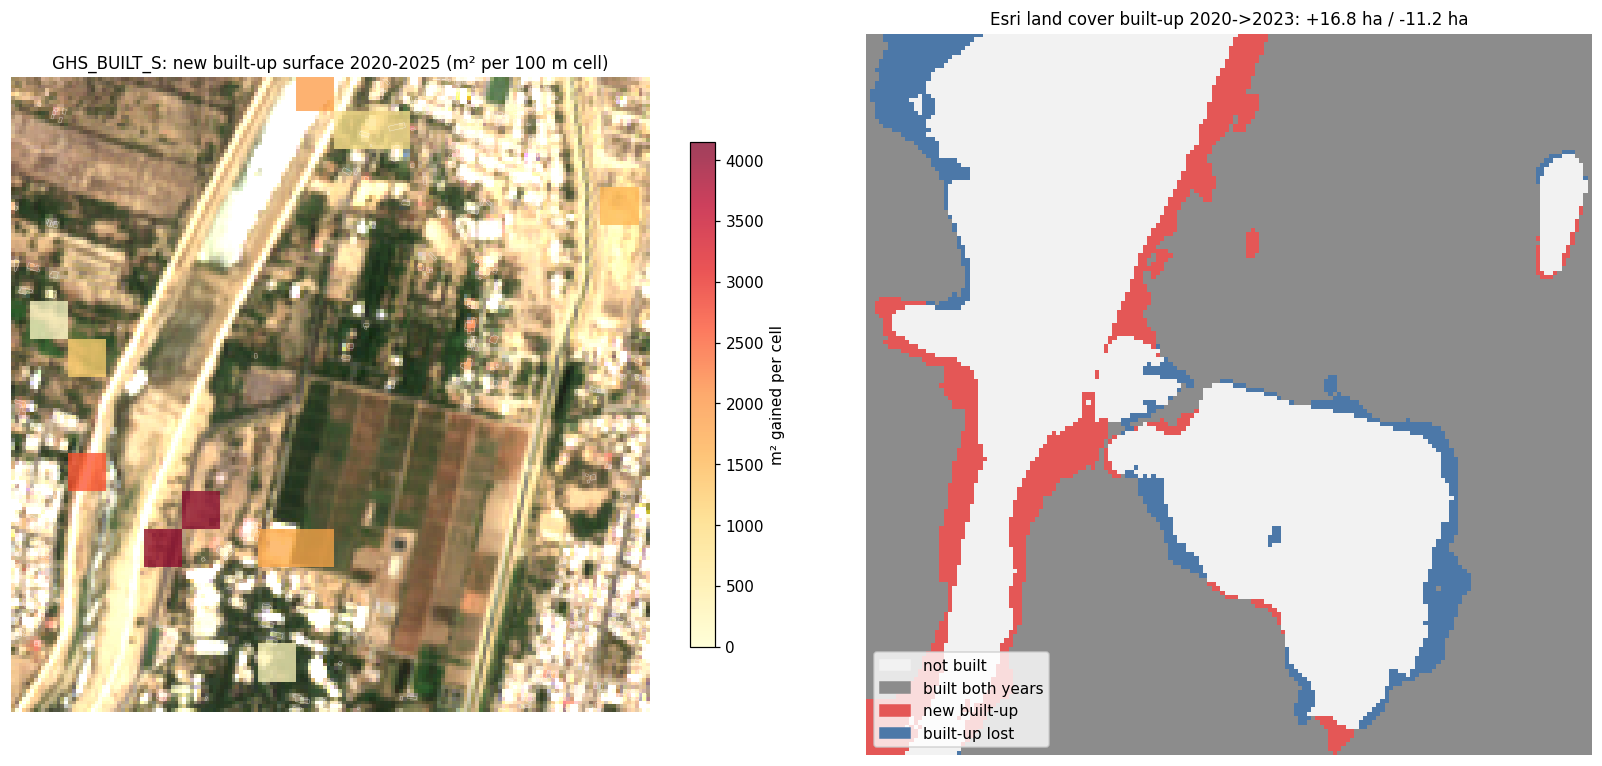

In [31]:
fig_new, _axes = plt.subplots(1, 2, figsize=(15, 7))
_ax = _axes[0]
_ax.imshow(rgb, extent=s2_extent)
_gain = np.ma.masked_where(dsurf <= 0, dsurf)
_im = _ax.imshow(_gain, extent=extent100, cmap="YlOrRd", alpha=0.75, vmin=0)
if len(buildings["Microsoft"]):
    buildings["Microsoft"].boundary.plot(ax=_ax, color="white", linewidth=0.2)
_ax.set_title(f"GHS_BUILT_S: new built-up surface {EPOCHS[0]}-{EPOCHS[1]} (m² per 100 m cell)")
_ax.set_xlim(s2_extent[0], s2_extent[1])
_ax.set_ylim(s2_extent[2], s2_extent[3])
_ax.set_axis_off()
fig_new.colorbar(_im, ax=_ax, shrink=0.7, label="m² gained per cell")

_ax = _axes[1]
_cols = ["#f2f2f2", "#8c8c8c", "#e45756", "#4c78a8"]
if ue_result.success:
    with rasterio.open(ue_result.output_path) as _src:
        _cls = _src.read(1).astype(float)
        _bb = _src.bounds
    _cls[_cls == 255] = np.nan
    _ax.imshow(_cls, cmap=ListedColormap(_cols), vmin=-0.5, vmax=3.5,
               extent=[_bb.left, _bb.right, _bb.bottom, _bb.top], interpolation="nearest")
    _s = ue_result.stats
    _ax.set_title(f"Esri land cover built-up {_s['year_before']}->{_s['year_after']}: "
                  f"+{_s['gain_ha']:.1f} ha / -{_s['loss_ha']:.1f} ha")
else:
    _ax.text(0.5, 0.5, f"urban_expansion failed:\n{ue_result.error}", ha="center", wrap=True)
_ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(
    _cols, ["not built", "built both years", "new built-up", "built-up lost"])], loc="lower left")
_ax.set_axis_off()
fig_new.tight_layout()
save_fig(fig_new, "fig_new")
plt.show()

In [32]:
new_sectors = sector_table(np.clip(dsurf, 0, None), "GHS_BUILT_S_gain_m2")
if ue_result.success:
    with rasterio.open(ue_result.output_path) as _src:
        _cls = _src.read(1)
        _px = abs(_src.transform.a * _src.transform.e)
    _esri = sector_table((_cls == 2).astype(float) * _px, "Esri_new_built_m2")
    new_sectors = new_sectors.merge(_esri, on="sector", suffixes=("", "_esri"))
new_sectors = pd.DataFrame(new_sectors).round(1)
new_sectors

,sector,GHS_BUILT_S_gain_m2,share_of_gain_%,Esri_new_built_m2,share_of_gain_%_esri
0,SW,8230.0,40.1,51400.0,30.6
1,W,3758.0,18.3,54000.0,32.2
2,S,3607.0,17.6,5800.0,3.5
3,N,3425.0,16.7,39800.0,23.7
4,NE,1492.0,7.3,2100.0,1.3
5,NW,0.0,0.0,0.0,0.0
6,Centre,0.0,0.0,13800.0,8.2
7,E,0.0,0.0,600.0,0.4
8,SE,0.0,0.0,200.0,0.1


In [33]:
_rows = []
if ue_result.success:
    with rasterio.open(ue_result.output_path) as _src:
        _new = _src.read(1) == 2
        _tr, _crs, _shape = _src.transform, _src.crs, (_src.height, _src.width)
    _masks = {}
    for _n, _g in buildings.items():
        if len(_g):
            _geoms = [(g, 1) for g in _g.to_crs(_crs).geometry.buffer(10) if g is not None and not g.is_empty]
            _masks[_n] = rasterize(_geoms, out_shape=_shape, transform=_tr, fill=0, dtype="uint8").astype(bool)
    if _masks:
        _any = np.logical_or.reduce(list(_masks.values()))
        for _n, _m in list(_masks.items()) + [("any of the three", _any)]:
            _rows.append({"published source": _n,
                          "new built-up pixels near a footprint_%": 100 * (_new & _m).sum() / max(_new.sum(), 1)})
new_check = pd.DataFrame(_rows).round(1)
new_check

,published source,new built-up pixels near a footprint_%
0,Microsoft,0.2
1,Google,14.0
2,OSM,0.2
3,any of the three,14.2


## 6. Question 4 - Where do we observe growth in building volume?
GHS_BUILT_V change 2020-2025 per 100 m cell, which is the same 100 m block size as in Session 2.

Figure saved: figures/fig_vol.png


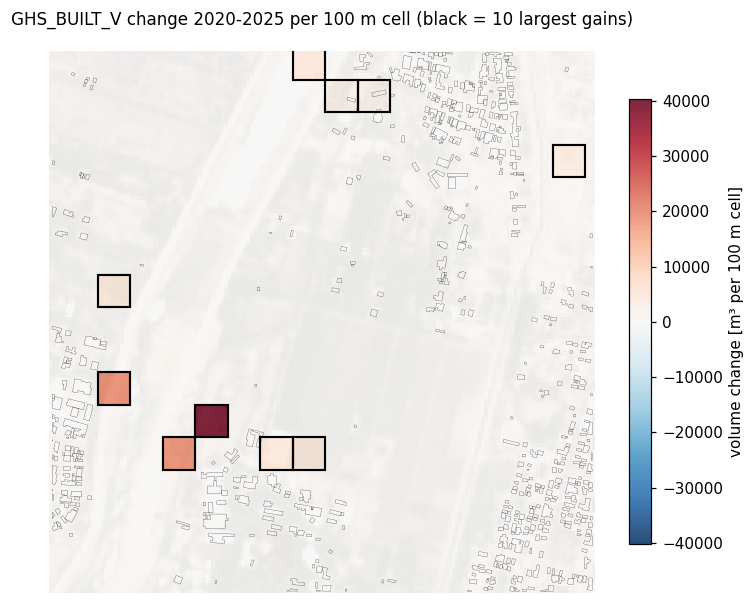

In [34]:
_lim = max(np.nanmax(np.abs(dvol)), 1)
fig_vol, _ax = plt.subplots(figsize=(8, 7))
_ax.imshow(rgb, extent=s2_extent, alpha=0.45)
_im = _ax.imshow(dvol, cmap="RdBu_r", vmin=-_lim, vmax=_lim, extent=extent100, alpha=0.85)
if len(buildings["Microsoft"]):
    buildings["Microsoft"].boundary.plot(ax=_ax, color="black", linewidth=0.15)
# outline the ten cells with the largest gain
for _idx in np.argsort(dvol, axis=None)[-10:]:
    _r, _c = np.unravel_index(_idx, dvol.shape)
    _ax.add_patch(Rectangle((extent100[0] + 100 * _c, extent100[3] - 100 * (_r + 1)), 100, 100,
                            fill=False, edgecolor="black", linewidth=1.4))
_ax.set_xlim(s2_extent[0], s2_extent[1])
_ax.set_ylim(s2_extent[2], s2_extent[3])
_ax.set_title(f"GHS_BUILT_V change {EPOCHS[0]}-{EPOCHS[1]} per 100 m cell (black = 10 largest gains)")
_ax.set_axis_off()
fig_vol.colorbar(_im, ax=_ax, shrink=0.75, label="volume change [m³ per 100 m cell]")
save_fig(fig_vol, "fig_vol")
plt.show()

In [35]:
vol_sectors = sector_table(dvol, "volume_change_m3")
_b = dvol.ravel()
block_stats = pd.DataFrame(
    {
        "cells": [_b.size],
        "cells_gaining": [int((_b > 0).sum())],
        "cells_losing": [int((_b < 0).sum())],
        "largest_gain_m3": [float(_b.max())],
        "largest_loss_m3": [float(_b.min())],
        "net_change_m3": [float(np.nansum(_b))],
    }
).round(0)
vol_sectors.round(0)

,sector,volume_change_m3,share_of_gain_%
0,SW,59450.0,55.0
1,W,24284.0,23.0
2,S,10554.0,10.0
3,N,9585.0,9.0
4,NE,3747.0,4.0
5,NW,0.0,0.0
6,Centre,0.0,0.0
7,E,0.0,0.0
8,SE,0.0,0.0


In [ ]:
block_stats

In [36]:
_y0, _y1 = EPOCHS
_grew = dsurf > 0
_built = surf[_y1] > 0

def _h(mask, y):
    s = surf[y][mask].sum()
    return vol[y][mask].sum() / s if s > 0 else np.nan

height_table = pd.DataFrame(
    {
        "cells": ["all built cells", "cells where built-up surface grew", "cells with no surface growth"],
        f"mean_height_{_y0}_m": [_h(_built, _y0), _h(_grew & _built, _y0), _h(~_grew & _built, _y0)],
        f"mean_height_{_y1}_m": [_h(_built, _y1), _h(_grew & _built, _y1), _h(~_grew & _built, _y1)],
    }
).round(2)
height_table

,cells,mean_height_2020_m,mean_height_2025_m
0,all built cells,5.30,5.30
1,cells where built-up surface grew,6.57,5.31
2,cells with no surface growth,5.30,5.30


In [37]:
_ue = (f"{100 * ue_result.stats['annual_growth_rate']:.2f} %" if ue_result.success else "n/a")
_y0, _y1 = EPOCHS
mo.md(f"""
## Summary of the numbers used in the report
| | value |
|---|---|
| World Population Review, 2025-2026 | {100 * wpr_rate_1y:.2f} % per year |
| GHS_POP AOI, {_y0}-{_y1} | {pop_table.iloc[0, 3]:.2f} % per year |
| GHS_POP city box, {_y0}-{_y1} | {pop_table.iloc[1, 3]:.2f} % per year |
| GHS_BUILT_S footprint extent, AOI, {_y0}-{_y1} | {100 * fp_cagr:.2f} % per year |
| GHS_BUILT_S footprint extent, city box, {_y0}-{_y1} | {built_table.loc[1, 'surface_growth_%_per_year']:.2f} % per year |
| GHS_BUILT_V building volume, AOI, {_y0}-{_y1} | {100 * vol_cagr:.2f} % per year |
| GHS_BUILT_V building volume, city box, {_y0}-{_y1} | {built_table.loc[1, 'volume_growth_%_per_year']:.2f} % per year |
| Esri built-up area (urban_expansion), AOI, 2020-2023 | {_ue} per year |
""")


## Summary of the numbers used in the report
| | value |
|---|---|
| World Population Review, 2025-2026 | 2.75 % per year |
| GHS_POP AOI, 2020-2025 | 2.94 % per year |
| GHS_POP city box, 2020-2025 | 1.16 % per year |
| GHS_BUILT_S footprint extent, AOI, 2020-2025 | 1.70 % per year |
| GHS_BUILT_S footprint extent, city box, 2020-2025 | 0.13 % per year |
| GHS_BUILT_V building volume, AOI, 2020-2025 | 1.97 % per year |
| GHS_BUILT_V building volume, city box, 2020-2025 | 0.08 % per year |
| Esri built-up area (urban_expansion), AOI, 2020-2023 | 1.07 % per year |


In [38]:
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
_parts = [f"Sentinel-2 date: {best_date.date()}"]
for _name, _df in [("pop_table", pop_table), ("built_table", built_table), ("area_check", area_check),
                   ("new_sectors", new_sectors), ("new_check", new_check), ("vol_sectors", vol_sectors),
                   ("block_stats", block_stats), ("height_table", height_table)]:
    _parts.append(f"=== {_name}\n{_df.round(2).to_string()}")
_parts.append("=== urban_expansion\n" + str({k: v for k, v in (ue_result.stats or {}).items() if k != "product_note"}))
report_values = "\n\n".join(_parts)
FIG_DIR.mkdir(exist_ok=True)
(FIG_DIR / "report_values.txt").write_text(report_values)
print(report_values)

Sentinel-2 date: 2026-10-05

=== pop_table
       area   pop_2020   pop_2025  growth_%_per_year
0       AOI    3602.93    4165.16               2.94
1  City box  493019.69  522191.16               1.16

=== built_table
       area  surface_2020_m2  surface_2025_m2  surface_growth_%_per_year  volume_2020_m3  volume_2025_m3  volume_growth_%_per_year  mean_height_2020_m  mean_height_2025_m
0       AOI         204630.0         222670.0                       1.70        982256.0       1083125.0                      1.97                4.80                4.86
1  City box       19288726.0       19416605.0                       0.13     138365117.0     138934212.0                      0.08                7.17                7.16

=== area_check
                            source  area_ha  annual_growth_%
0                 GHS_BUILT_S 2020    20.46              NaN
1                 GHS_BUILT_S 2025    22.27             1.70
2        Esri 10 m land cover 2020   172.06              NaN
3       